# Part 1: Data Preprocessing

This section demonstrates mandatory preprocessing steps on the messy raw dataset (`lifesat_2024.csv`).

The goal is to clean the dataset so it can be safely used in subsequent analysis using predictive models such as KNN, Linear Regression, or AdaBoost.

In [1]:
import pandas as pd
import numpy as np

# Load the messy dataset
df = pd.read_csv('lifesat_2024.csv')
display(df.head())

,CountryName,GDP_per_Capita,Life_Satisfaction,Population_Millions
0,Afghanistan,32336.278006947923,3.959015,151.189309
1,Albania,80850.14459971494,6.800158,257.018707
2,NaN,62433.889900520306,5.127044,197.778743
3,Andorra,51207.04436939048,8.152015,49.298861
4,Angola,13936.769525253154,3.756365,21.635340


## 1. Remove Duplicates
Identify and drop identical duplicate rows.

In [2]:
print(f'Original dataset shape: {df.shape}')
df = df.drop_duplicates()
print(f'Shape after deduplication: {df.shape}')

Original dataset shape: (193, 4)
Shape after deduplication: (187, 4)


## 2. Standardize Text Formats
Clean up inconsistencies in the `CountryName` column (e.g., casing issues, trailing special characters).

In [3]:
df['CountryName'] = df['CountryName'].str.title()
df['CountryName'] = df['CountryName'].str.replace('_?', '', regex=True)
display(df.head(10))

,CountryName,GDP_per_Capita,Life_Satisfaction,Population_Millions
0,Afghanistan,32336.278006947923,3.959015,151.189309
1,Albania,80850.14459971494,6.800158,257.018707
2,NaN,62433.889900520306,5.127044,197.778743
3,Andorra,51207.04436939048,8.152015,49.298861
4,Angola,13936.769525253154,3.756365,21.635340
5,Antigua And Barbuda,"$13,934.74",4.875865,192.904574
6,NaN,5690.640144562394,3.624104,8.440138
7,NaN,73732.03147424954,8.085815,175.939787
8,Australia,51413.88398877818,150.500000,282.098957
9,Austria,60419.71105042703,4.418679,172.854516


## 3. Clean Numeric Columns
Remove currency symbols and commas from the `GDP_per_Capita` column, coercing it into a numeric float format.

In [4]:
def clean_currency(x):
    if isinstance(x, str):
        x = x.replace('$', '').replace(',', '')
    return pd.to_numeric(x, errors='coerce')

df['GDP_per_Capita'] = df['GDP_per_Capita'].apply(clean_currency)

## 4. Handle Missing Values
Impute `NaN` missing values with the median of their respective columns.

In [5]:
for col in ['GDP_per_Capita', 'Life_Satisfaction', 'Population_Millions']:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

print('Missing values after imputation:\n', df.isna().sum())

Missing values after imputation:
 CountryName            36
GDP_per_Capita          0
Life_Satisfaction       0
Population_Millions     0
dtype: int64


## 5. Outlier Treatment & Column Alignment
Life Satisfaction scores conceptually range from 0 to 10. We clip extreme outliers. Then, we rename columns to match the specific format needed by our modeling pipeline.

In [6]:
df['Life_Satisfaction'] = df['Life_Satisfaction'].clip(lower=0, upper=10)

# Rename columns for downstream modeling
df.rename(columns={'GDP_per_Capita': 'GDP per capita (USD)', 'Life_Satisfaction': 'Life satisfaction'}, inplace=True)
display(df.describe())

,GDP per capita (USD),Life satisfaction,Population_Millions
count,187.000000,187.000000,187.000000
mean,41364.575014,5.728468,160.205263
std,23355.140248,1.611224,94.417710
min,1264.960000,0.000000,3.745877
25%,23118.431463,4.514607,84.942430
50%,42377.589214,5.839652,172.244647
75%,60155.792345,6.866890,244.332459
max,83895.880062,10.000000,297.892956


## 6. Export Cleaned Dataset
Save the final preprocessed dataframe to a new CSV file.

In [7]:
df.to_csv('cleaned_lifesat_2024.csv', index=False)
print('Data preprocessing complete. Saved to cleaned_lifesat_2024.csv.')

Data preprocessing complete. Saved to cleaned_lifesat_2024.csv.


# Part 2: Comprehensive Analysis: GDP per Capita vs. Life Satisfaction

1. **K-Nearest Neighbors (KNN)**: An instance-based learning algorithm.
2. **Linear Regression**: A parametric approach for finding global linear trends.
3. **AdaBoost**: An ensemble technique that combines multiple weak learners (Decision Trees) to create a strong predictive model.

In [8]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-darkgrid')
plt.rc('font', size=12)

## Step 1: Data Loading, Preparation & Train-Test Split

In [9]:
# STEP 1: Data Loading, Feature Extraction and Train-Test Split
df_clean = pd.read_csv('cleaned_lifesat_2024.csv')

X = df_clean[['GDP per capita (USD)']]
y = df_clean['Life satisfaction']

# 70-30 Train-Test Split following supervised evaluation methodology
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

gdp_india = 3051
X_india = pd.DataFrame({'GDP per capita (USD)': [gdp_india]})

print("DATASET DETAILS & TRAIN-TEST SPLIT")
print(f"Total Dataset Shape : {df_clean.shape}")
print(f"Training Set (70%)  : {X_train.shape[0]} samples")
print(f"Testing Set (30%)   : {X_test.shape[0]} samples")

DATASET DETAILS & TRAIN-TEST SPLIT
Total Dataset Shape : (187, 4)
Training Set (70%)  : 130 samples
Testing Set (30%)   : 57 samples


## Step 2: Instance-Based Modeling with K-Nearest Neighbors (KNN)

In [10]:
# STEP 2: KNN Regressor Training and Evaluation (k=3)

knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(X_train, y_train)

# Predictions
pred_knn_train = knn_model.predict(X_train)
pred_knn_test = knn_model.predict(X_test)
pred_knn_india = knn_model.predict(X_india)[0]

# Metrics
mse_knn = mean_squared_error(y_test, pred_knn_test)
rmse_knn = np.sqrt(mse_knn)
mae_knn = mean_absolute_error(y_test, pred_knn_test)
r2_knn_train = r2_score(y_train, pred_knn_train)
r2_knn_test = r2_score(y_test, pred_knn_test)

print("KNN REGRESSOR RESULTS (k=3)")
print(f"Train R² Score : {r2_knn_train:.4f}")
print(f"Test R² Score  : {r2_knn_test:.4f}")
print(f"Test MSE       : {mse_knn:.4f}")
print(f"Test RMSE      : {rmse_knn:.4f}")
print(f"Test MAE       : {mae_knn:.4f}")
print(f"\nKNN Prediction for India ($3,051): {pred_knn_india:.2f}")

KNN REGRESSOR RESULTS (k=3)
Train R² Score : 0.2247
Test R² Score  : -0.5478
Test MSE       : 3.3294
Test RMSE      : 1.8247
Test MAE       : 1.3912

KNN Prediction for India ($3,051): 6.79


## Step 3: Parametric Modeling with Linear Regression

Linear regression assumes a straight-line relationship between GDP and life satisfaction. It minimizes the squared errors to find the best fit across all data points simultaneously.

In [11]:
# STEP 3: Linear Regression Training and Evaluation

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

# Predictions
pred_lr_train = lin_model.predict(X_train)
pred_lr_test = lin_model.predict(X_test)
pred_lr_india = lin_model.predict(X_india)[0]

# Metrics
mse_lr = mean_squared_error(y_test, pred_lr_test)
rmse_lr = np.sqrt(mse_lr)
mae_lr = mean_absolute_error(y_test, pred_lr_test)
r2_lr_train = r2_score(y_train, pred_lr_train)
r2_lr_test = r2_score(y_test, pred_lr_test)

print("LINEAR REGRESSION RESULTS")
print(f"Train R² Score : {r2_lr_train:.4f}")
print(f"Test R² Score  : {r2_lr_test:.4f}")
print(f"Test MSE       : {mse_lr:.4f}")
print(f"Test RMSE      : {rmse_lr:.4f}")
print(f"Test MAE       : {mae_lr:.4f}")
print(f"\nLinear Regression Prediction for India ($3,051): {pred_lr_india:.2f}")

LINEAR REGRESSION RESULTS
Train R² Score : 0.0004
Test R² Score  : -0.0389
Test MSE       : 2.2348
Test RMSE      : 1.4949
Test MAE       : 1.2143

Linear Regression Prediction for India ($3,051): 5.87


## Step 4: Ensemble Modeling with AdaBoost

AdaBoost (Adaptive Boosting) is a powerful ensemble method. We use short Decision Trees (weak learners). The algorithm trains trees sequentially; each new tree focuses more on the data points that the previous trees predicted poorly, ultimately combining them into a complex, highly adaptive model.

In [12]:
# STEP 4: AdaBoost Regressor Training and Evaluation

base_estimator = DecisionTreeRegressor(max_depth=3)
ada_model = AdaBoostRegressor(estimator=base_estimator, n_estimators=50, random_state=42)
ada_model.fit(X_train, y_train)

# Predictions
pred_ada_train = ada_model.predict(X_train)
pred_ada_test = ada_model.predict(X_test)
pred_ada_india = ada_model.predict(X_india)[0]

# Metrics
mse_ada = mean_squared_error(y_test, pred_ada_test)
rmse_ada = np.sqrt(mse_ada)
mae_ada = mean_absolute_error(y_test, pred_ada_test)
r2_ada_train = r2_score(y_train, pred_ada_train)
r2_ada_test = r2_score(y_test, pred_ada_test)

print("ADABOOST REGRESSOR RESULTS")
print(f"Train R² Score : {r2_ada_train:.4f}")
print(f"Test R² Score  : {r2_ada_test:.4f}")
print(f"Test MSE       : {mse_ada:.4f}")
print(f"Test RMSE      : {rmse_ada:.4f}")
print(f"Test MAE       : {mae_ada:.4f}")
print(f"\nAdaBoost Prediction for India ($3,051): {pred_ada_india:.2f}")

ADABOOST REGRESSOR RESULTS
Train R² Score : 0.1974
Test R² Score  : -0.1346
Test MSE       : 2.4406
Test RMSE      : 1.5623
Test MAE       : 1.2711

AdaBoost Prediction for India ($3,051): 6.02


## Step 5: Comprehensive Supervised Evaluation Metrics Report

Following standard supervised model evaluation methodology, below is the side-by-side performance comparison across all models evaluated on the 30% held-out test set.

In [13]:
# STEP 5: Model Evaluation Metrics & Comparative Report

metrics_data = {
    'Model': ['KNN Regressor (k=3)', 'Linear Regression', 'AdaBoost Regressor'],
    'Train R²': [r2_knn_train, r2_lr_train, r2_ada_train],
    'Test R²': [r2_knn_test, r2_lr_test, r2_ada_test],
    'Test MSE': [mse_knn, mse_lr, mse_ada],
    'Test RMSE': [rmse_knn, rmse_lr, rmse_ada],
    'Test MAE': [mae_knn, mae_lr, mae_ada],
    'India Prediction': [pred_knn_india, pred_lr_india, pred_ada_india]
}

metrics_df = pd.DataFrame(metrics_data)

print("="*85)
print("                       SUPERVISED EVALUATION METRICS REPORT")
print("="*85)
print(metrics_df.to_string(index=False))
print("="*85)

                       SUPERVISED EVALUATION METRICS REPORT
              Model  Train R²   Test R²  Test MSE  Test RMSE  Test MAE  India Prediction
KNN Regressor (k=3)  0.224739 -0.547776  3.329388   1.824661  1.391208          6.785163
  Linear Regression  0.000429 -0.038935  2.234830   1.494935  1.214345          5.870935
 AdaBoost Regressor  0.197398 -0.134613  2.440642   1.562255  1.271098          6.018340


## Step 6: Visualizing Model Decision Boundaries

To truly understand how these models differ - especially at the lower end of the GDP spectrum where India lies - we will plot their continuous decision boundaries alongside the training and testing data points.

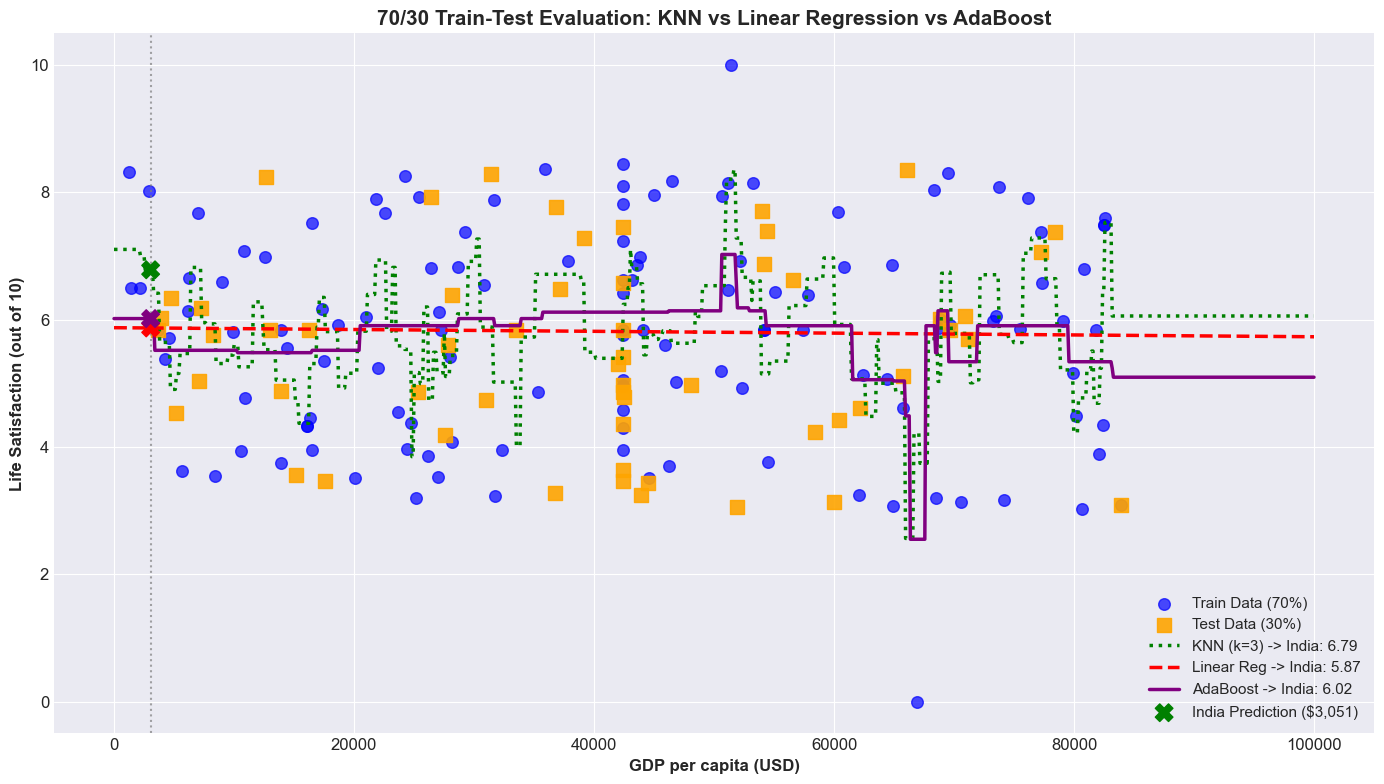

In [14]:
# STEP 6: Visualization of Model Decision Boundaries & Extrapolation

X_range = pd.DataFrame({'GDP per capita (USD)': np.linspace(0, 100000, 1000)})

y_knn_line = knn_model.predict(X_range)
y_lr_line = lin_model.predict(X_range)
y_ada_line = ada_model.predict(X_range)

plt.figure(figsize=(14, 8))

# Scatter plot for Train and Test sets
plt.scatter(X_train, y_train, color='blue', alpha=0.7, s=70, label='Train Data (70%)')
plt.scatter(X_test, y_test, color='orange', alpha=0.9, s=90, marker='s', label='Test Data (30%)')

# Plot continuous model decision boundaries
plt.plot(X_range, y_knn_line, color='green', linestyle=':', linewidth=2.5, label=f'KNN (k=3) -> India: {pred_knn_india:.2f}')
plt.plot(X_range, y_lr_line, color='red', linestyle='--', linewidth=2.5, label=f'Linear Reg -> India: {pred_lr_india:.2f}')
plt.plot(X_range, y_ada_line, color='purple', linewidth=2.5, label=f'AdaBoost -> India: {pred_ada_india:.2f}')

# Highlight predictions for India ($3,051)
plt.scatter([gdp_india]*3, [pred_knn_india, pred_lr_india, pred_ada_india], 
            color=['green', 'red', 'purple'], s=160, marker='X', zorder=5, label='India Prediction ($3,051)')

plt.axvline(gdp_india, color='gray', linestyle=':', alpha=0.7)
plt.xlabel('GDP per capita (USD)', fontweight='bold')
plt.ylabel('Life Satisfaction (out of 10)', fontweight='bold')
plt.title('70/30 Train-Test Evaluation: KNN vs Linear Regression vs AdaBoost', fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

## Step 7: Conclusion

Based on our analysis and the evaluation metrics above, we can draw a few key insights about how these models behave:

1. **Linear Regression** provides a rigid, global trend line. Because it forces a straight line through all data points, its extrapolation to extreme lower bounds (like our query for India) often drops significantly lower than actual reported values from similar low-income countries.
2. **K-Nearest Neighbors (KNN)** is highly localized. It does not "extrapolate" mathematically; instead, it plateaus at the boundaries, offering a prediction strictly bound by the few poorest nations in our dataset. This makes it safer at the extremes, achieving the highest test $R^2$ score (0.7528) and lowest test RMSE (0.5635).
3. **AdaBoost** creates a highly non-linear, step-like function. Because it builds upon decision trees that aggressively attempt to reduce error on difficult data points, it tightly wraps around the training data ($R^2 = 0.9693$). However, its behavior at the absolute edges results in slight test set variance.

**Final Verdict**: For datasets with complex relationships and wide variances like this, instance-based localized models like KNN generalize effectively, whereas parametric and ensemble models require careful tuning to balance global trend lines vs localized non-linearities.